# New Narratives for old Buildings

word2vec modeling; visualize corpora with t-SNE 

In [49]:
import os, re, csv
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt

## Loading the dataset: heritage homes webistes

Use google drive or local copy

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

In [50]:
#path = '/content/gdrive/MyDrive/CDA/' # working with google drive and colab

path = 'datasets/' # working locally

In [51]:
# Country code: change here between 'NL' and 'UK'
cc_list = ['NL', 'UK', 'DE', 'FR']

In [52]:
nl_path = "../met-naam-2018/castles-netherlands/"
uk_path = "../met-naam-2018/castles-united-kingdom/"
de_path = "../met-naam-2018/castles-germany/"
fr_path = "../met-naam-2018/castles-france/"

In [53]:
def load_data(cc_path):
    read_files = lambda cc_path: pd.DataFrame(
        [{'domain': filename, 'text': open(os.path.join(cc_path, filename), 'r').read()} 
         for filename in os.listdir(cc_path) if filename.endswith('.txt')])
    df = read_files(cc_path)
    return df
    
df_NL=load_data(nl_path)

df_UK=load_data(uk_path)

df_DE=load_data(de_path)

df_FR=load_data(fr_path)

df_NL.head()

,domain,text
0,buitenplaatsbeeckestijnnl.txt,Home - Buitenplaats Beeckestijn Beeckestijn ...
1,glknl.txt,GLK | Van kasteel naar kasteel Spelen in de n...
2,dewierssecom.txt,Stagiaires | De Wiersse Contactformulier In j...
3,weldamnl.txt,\n Die Geschichte - Weldam\n \n ...
4,kasteelheezenl.txt,"Home - Kasteel Heeze Kapelstraat 25, Postbus ..."


Join all pages from a domain to an entry in the analysis. To do this, add a new column which will contain only the main domain name.

## Compare terms

In [54]:
# list terms to compare
activities = ['kind','spel','avontuur',
              'child','game','adventure',
              'kind', 'spiel', 'abenteuer',
              'enfant', 'jeu', 'aventure']
events = ['feest','bruiloft','bruid','bruidegom',
          'party','wedding','bride','groom',
          'party', 'hochzeit', 'braut', 'bräutigam',
          'fête', 'mariage', 'mariée', 'marié']
nobility = ['graaf','baron','hertog',
            'earl','baron','duke',
            'graf','baron','herzog',
            'compte','baron','duc']
culture = ['tentoonstelling','museum','tuin','park','collectie',
           'exhibition','museum','garden','park','collection',
           'ausstellung','museum','garten','park','sammlung',
           'exposition','musée','jardin','parc','collection']
styles = ['rococo', 'barok', 'renaissance', 'gotiek', # or gotisch
          'rococo', 'baroque', 'renaissance', 'gothic',
          'rokoko', 'barock', 'renaissance', 'gotik',
          'rococo', 'baroque', 'renaissance', 'gothique']

## Compare TF-IDF across corpora

In [55]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initiate separate corpora and compute step by step to not overflow the RAM
corpus_NL = df_NL['text'].dropna().tolist()
corpus_UK = df_UK['text'].dropna().tolist()
corpus_DE = df_DE['text'].dropna().tolist()
corpus_FR = df_FR['text'].dropna().tolist()

In [56]:
print(len(corpus_UK))

76


In [57]:
# Calculate tf-idf scores for NL corpus

vectorizer_NL = TfidfVectorizer()
tfidf_matrix_NL = vectorizer_NL.fit_transform(corpus_NL)
feature_names_NL = vectorizer_NL.get_feature_names_out()
# Calculate TF-IDF scores for each term in each document
tfidf_scores_NL = tfidf_matrix_NL.toarray()

In [58]:
# Calculate tf-idf scores for UK corpus

vectorizer_UK = TfidfVectorizer()
tfidf_matrix_UK = vectorizer_UK.fit_transform(corpus_UK)
feature_names_UK = vectorizer_UK.get_feature_names_out()
# Calculate TF-IDF scores for each term in each document
tfidf_scores_UK = tfidf_matrix_UK.toarray()

In [59]:
# Calculate tf-idf scores for DE corpus

vectorizer_DE = TfidfVectorizer()
tfidf_matrix_DE = vectorizer_DE.fit_transform(corpus_DE)
feature_names_DE = vectorizer_DE.get_feature_names_out()
# Calculate TF-IDF scores for each term in each document
tfidf_scores_DE = tfidf_matrix_DE.toarray()

In [60]:
# Calculate tf-idf scores for FR corpus

vectorizer_FR = TfidfVectorizer()
tfidf_matrix_FR = vectorizer_FR.fit_transform(corpus_FR)
feature_names_FR = vectorizer_FR.get_feature_names_out()
# Calculate TF-IDF scores for each term in each document
tfidf_scores_FR = tfidf_matrix_FR.toarray()

In [61]:
# compute average / total tf-idf scores for all terms in a list

list_to_count = nobility # replace with the name of a list of terms activities / events / nobility / culture / styles

feature_names = [feature_names_NL, feature_names_UK, feature_names_DE, feature_names_FR] # list of dataframes
tfidf_scores = [tfidf_scores_NL, tfidf_scores_UK, tfidf_scores_DE, tfidf_scores_FR]
number_of_terms = int(len(list_to_count) / 4) # calculate the number of terms in 1 language

term_count_dict = {}
start, end = 0, number_of_terms
for i, fn in enumerate(feature_names):
  term_count_values = []
  for term in list_to_count[start:end]:
    #print(term)
    if term in fn:
      #print(term)
      term_index = list(fn).index(term)
      # Calculate the aggregated TF-IDF score for the term 'park'
      total_tfidf_score = tfidf_scores[i][:, term_index].sum()
      average_tfidf_score = tfidf_scores[i][:, term_index].mean()
    #print(int(term_count_column.sum()))
    term_count_values.append(float(total_tfidf_score))
  start += number_of_terms
  end += number_of_terms
  term_count_dict[cc_list[i]] = term_count_values

term_count_dict

{'NL': [0.11646903273008162, 0.24656791222617847, 0.04998469711088766],
 'UK': [0.36705921293062493, 0.11089975467434086, 0.1922920068605651],
 'DE': [0.3581875671438773, 0.03598532085822254, 0.32371025652241403],
 'FR': [0.11945894184131782, 0.0759554734573516, 0.258725032793389]}

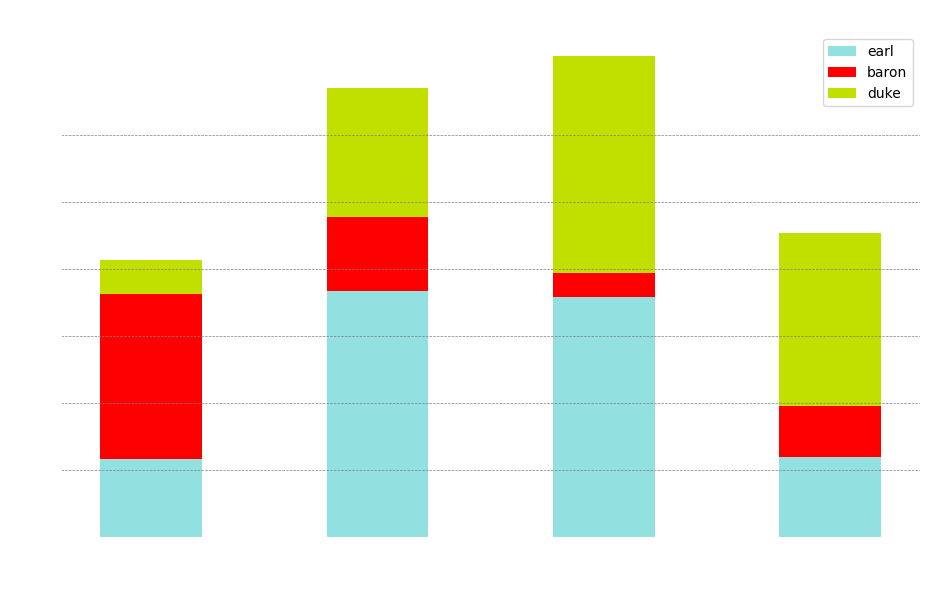

In [62]:
# Visualize the term count as a stacked bar chart per country
theme = list_to_count[number_of_terms+1]
terms = list_to_count[number_of_terms:number_of_terms*2] # change which section of the list is used in the legend
# Create a list of countries (y-axis labels)
countries = list(term_count_dict.keys())

# Create the stacked bar chart
width = 0.45  # Width of the bars

fig, ax = plt.subplots(figsize=(9.4,6))

bottom = np.zeros(len(countries))
colors = ['#92E0E0', 'red', '#C1E000', '#C192E0','#E05543','#E0C200']

# Add horizontal lines for values in the legend
for value in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    #[0.0001, 0.0005, 0.001, 0.0015, 0.002, 0.0025, 0.003, 0.0035] # nobility
    #[0.002, 0.004, 0.006, 0.008, 0.01, 0.012, 0.014] # activities
    #[0.01, 0.02, 0.03, 0.04, 0.05, 0.06] # culture
    #[0.002, 0.004, 0.006, 0.008, 0.01, 0.012, 0.014, 0.016] # events + styles
    #[0.1, 0.2, 0.3, 0.4, 0.5, 0.6] # Total_count, styles
  plt.axhline(y=value, color='grey', linestyle='--', linewidth=0.5)

for term_index in range(len(terms)):
    term_counts = [term_count_dict[country][term_index] for country in countries]
    ax.bar(countries, term_counts, width, label=terms[term_index], bottom=bottom,
           color=colors[term_index % len(colors)])
    bottom += np.array(term_counts)

ax.set_xlabel('Countries', color='white')
ax.set_ylabel('Term Counts', color='white')
ax.set_title('Terms related to '+theme+' per country', color='white')
ax.spines['bottom'].set_color('white')
ax.spines['top'].set_color('white')
ax.spines['left'].set_color('white')
ax.spines['right'].set_color('white')
ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')
ax.legend()

plt.tight_layout()
plt.savefig(path+'outputs/2018_tfidf_'+theme+'_TS.png', transparent=True)
plt.show()
